# Import Libraries

In [360]:
# load libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

# Load Dataset

In [361]:
loan_data = pd.read_csv("/Users/macbookpro/Desktop/ML & DL & GENAI Projects/Loan Approval Prediction/data/LoanApprovalPrediction.csv")
loan_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
593,LP002978,Female,No,0.0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
594,LP002979,Male,Yes,3.0,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
595,LP002983,Male,Yes,1.0,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
596,LP002984,Male,Yes,2.0,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


# Data Preprocessing

In [362]:
# first 5 rows
loan_data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [363]:
# last 5 rows
loan_data.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
593,LP002978,Female,No,0.0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
594,LP002979,Male,Yes,3.0,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
595,LP002983,Male,Yes,1.0,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
596,LP002984,Male,Yes,2.0,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
597,LP002990,Female,No,0.0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [364]:
# check for missing values
loan_data.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents           12
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           21
Loan_Amount_Term     14
Credit_History       49
Property_Area         0
Loan_Status           0
dtype: int64

In [365]:
# number of columns of object datatypes
obj = (loan_data.dtypes == 'object')
print("Categorical Columns :", len(list(obj[obj].index)))

Categorical Columns : 7


In [366]:
# drop the Loan_ID column
loan_data.drop(['Loan_ID'], axis=1, inplace=True)
loan_data

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
593,Female,No,0.0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
594,Male,Yes,3.0,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
595,Male,Yes,1.0,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
596,Male,Yes,2.0,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [367]:
# convert the categorical columns into an int
label_encoder = preprocessing.LabelEncoder()
obj = (loan_data.dtypes == 'object')
for col in list(obj[obj].index):
    loan_data[col] = label_encoder.fit_transform(loan_data[col])

In [368]:
# check number of columns with datatype == object
obj = (loan_data.dtypes == 'object')
print("Categorical Variables :", len(list(obj[obj].index)))

Categorical Variables : 0


In [369]:
# first 5 rows
loan_data.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0.0,0,0,5849,0.0,NaN,360.0,1.0,2,1
1,1,1,1.0,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0.0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0.0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0.0,0,0,6000,0.0,141.0,360.0,1.0,2,1


## Married:       ## Education:             ## Self-Employed
## Yes ==> 1      ## Graduate ==> 0         ## Yes ==> 1
## No ==> 0       ## Not Graduate ==> 1     ## No ==> 0

In [370]:
# check for missing values in columns
for col in loan_data.columns:
  loan_data[col] = loan_data[col].fillna(loan_data[col].mean()) 
 
loan_data.isna().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [371]:
# convert the Loan_Status Column Y and N into 1 and 0
loan_data['Loan_Status'] = loan_data['Loan_Status'].replace({
    'Y': 1,
    'N': 0
})

In [372]:
# first 5 rows
loan_data.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0.0,0,0,5849,0.0,144.968804,360.0,1.0,2,1
1,1,1,1.0,0,0,4583,1508.0,128.000000,360.0,1.0,0,0
2,1,1,0.0,0,1,3000,0.0,66.000000,360.0,1.0,2,1
3,1,1,0.0,1,0,2583,2358.0,120.000000,360.0,1.0,2,1
4,1,0,0.0,0,0,6000,0.0,141.000000,360.0,1.0,2,1


# Loan Status
## Yes ==> 1
## No ==> 0

In [373]:
# correspondent values of Loan Status column
print(loan_data['Loan_Status'].value_counts())

Loan_Status
1    411
0    187
Name: count, dtype: int64


# Data Splitting

In [374]:
# split the features from the Target
X = loan_data.drop('Loan_Status', axis=1)
y = loan_data['Loan_Status']

In [375]:
# data splitting
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [376]:
# shape of the X and Y
X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((598, 11), (598,), (418, 11), (180, 11), (418,), (180,))

# Model Training

### Prediction on the Training Data

In [377]:
knn = KNeighborsClassifier(n_neighbors=3)
rfc = RandomForestClassifier(n_estimators = 7,
                             criterion = 'entropy',
                             random_state =7)
svc = SVC()
lc = LogisticRegression()

# making predictions on the training set
for clf in (rfc, knn, svc,lc):
    clf.fit(X_train, y_train)
    Y_pred = clf.predict(X_train)
    print("Accuracy score of ",
          clf.__class__.__name__,
          "=",100*metrics.accuracy_score(y_train, 
                                         Y_pred))

Accuracy score of  RandomForestClassifier = 96.65071770334929
Accuracy score of  KNeighborsClassifier = 76.55502392344498
Accuracy score of  SVC = 68.89952153110048
Accuracy score of  LogisticRegression = 81.10047846889952


/opt/miniconda3/envs/ml_env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Prediction on Testing Data

In [378]:
# making predictions on testing data
for clf in (rfc, knn, svc, lc):
    clf.fit(X_train, y_train)
    Y_pred = clf.predict(X_test)
    print("Accuracy Score of ", clf.__class__.__name__,
          "=", 100 * metrics.accuracy_score(y_test, Y_pred))

Accuracy Score of  RandomForestClassifier = 78.88888888888889
Accuracy Score of  KNeighborsClassifier = 65.0
Accuracy Score of  SVC = 68.88888888888889
Accuracy Score of  LogisticRegression = 79.44444444444444


/opt/miniconda3/envs/ml_env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Data Visualization

In [379]:
# visualize all the unique value in the columns
obj = (loan_data.dtypes == 'object')
object_cols = list(obj[obj].index)
plt.figure(figsize=(18,36))
index = 1

for col in object_cols:
    y = loan_data[col].value_counts()
    plt.su(11,4,index)
    plt.xticks(rotation=90)
    sns.barplot(x=list(y.index), y=y)
    index +=1

<Figure size 1800x3600 with 0 Axes>

<Axes: >

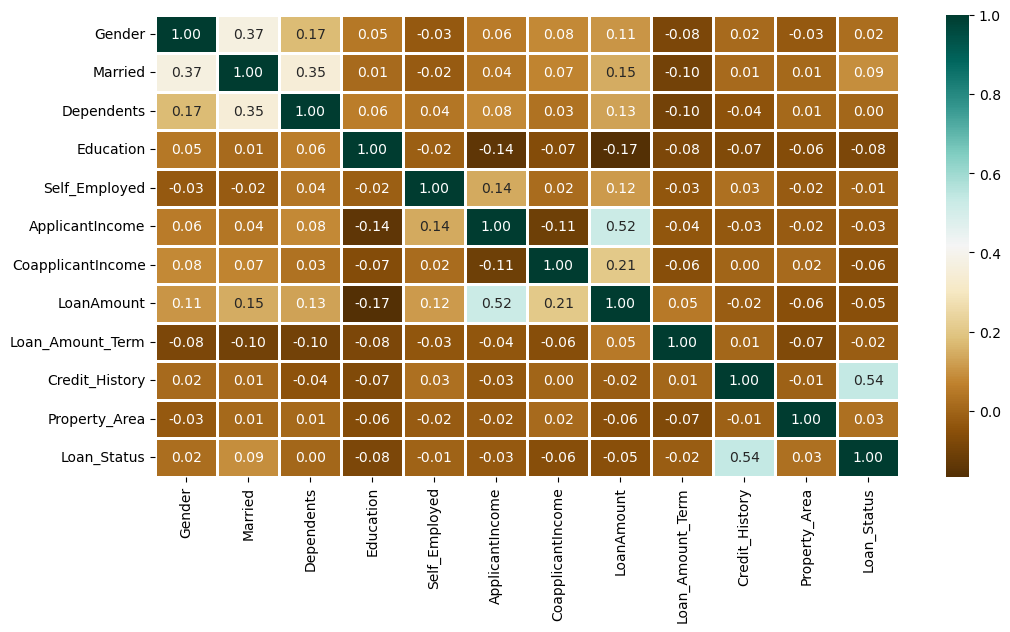

In [380]:
# heatmap
plt.figure(figsize=(12,6))
sns.heatmap(loan_data.corr(), cmap='BrBG', fmt='.2f',
            linewidths=2, annot=True)


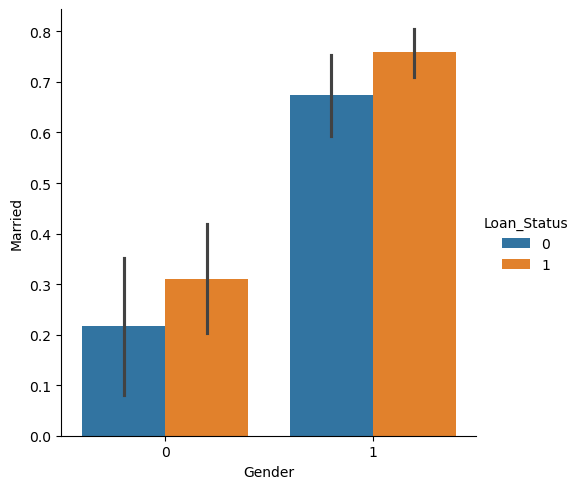

In [381]:
# catplot
sns.catplot(x='Gender', y='Married',
            hue='Loan_Status',
            kind='bar',
            data=loan_data)

In [ ]:
# from sklearn.svm import SVC
from sklearn import svm
classifier = svm.SVC(kernel='linear')
classifier.fit(X_train, y_train)

SVC(kernel='linear')

# Building a Predictive System

In [2]:
# input_data = (1,0,0.0,0,0,5849,0.0,144.968804,360.0,1.0,2,1) # 1 - Yes
# # input_data = (1,1,1.0,0,0,4583,1508.0,128.000000,360.0,1.0,0,0) 0 - # No

# # change input_data into a numpy array
# input_data_as_numpy_array = np.asarray(input_data)

# # reshape the data array for predicting 1 instance
# input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)

# # prediction
# prediction = classifier.predict(input_data_reshaped)
# print(prediction)

# if (prediction[0] == 0):
#     print("Loan NOT Approved")
# else:
#     print("Loan APPROVED")

# Save the model

In [1]:
# load the pickle library
# import pickle